# Zero-Day Network Attack Detection with QORC

This notebook is a beginner-friendly walkthrough of using a **Quantum Optical Reservoir Computer (QORC)** to spot unusual network connections in the NSL-KDD dataset.

Each row in the data describes one network connection. We will teach models about normal connections and one known attack family (DoS), then test whether they can recognize attack families they never saw during training. That is a simplified experiment in **zero-day detection**.

## The journey
1. **Network dataset:** inspect the data and create a train/test split that keeps selected attack families unseen.
2. **Build the QORC:** turn each connection into four values, encode them as optical phases, and simulate a small photonic circuit.
3. **Training process:** compare a supervised classifier with detectors trained only on normal traffic.
4. **Compare and conclude:** review attack detection and false alarms, then discuss limitations.

> **Before you start:** keep `NSL_KDD_labeled.csv` in this folder and install packages from [`requirements.txt`](requirements.txt). In VS Code, select this folder's `.venv` as the notebook kernel. The correct Quandela package is named `perceval-quandela`, while Python imports it as `perceval`. If `from perceval.simulators import Simulator` raises `ModuleNotFoundError`, the kernel may have the unrelated PyPI package named `perceval`; remove that package from the selected environment with `python -m pip uninstall -y perceval`, then run `python -m pip install -r requirements.txt` and reselect the `.venv` kernel.

In [56]:
import sys, importlib.util
try:
    import perceval as _p
    assert importlib.util.find_spec("perceval.simulators") and importlib.util.find_spec("sklearn") and importlib.util.find_spec("merlin")
    print("OK: Quandela perceval", _p.__version__, "|", sys.executable)
except Exception as e:
    raise RuntimeError(
        f"Wrong kernel environment: {sys.executable}\n"
        "Needs Quandela's 'perceval-quandela' + 'merlinquantum' + scikit-learn. The 'perceval' package (Bitergia/GrimoireLab) "
        "is a different project with the same module name.\n"
        "Fix: select the kernel '.venv' in oct_27_try, or run: "
        "pip uninstall -y perceval && pip install perceval-quandela merlinquantum scikit-learn") from e

OK: Quandela perceval 1.2.1 | c:\Users\binh1\miniconda3\envs\py3.10_pytorch\python.exe


In [57]:
import numpy as np, pandas as pd, time
import matplotlib.pyplot as plt
import perceval as pcvl
from perceval.backends import SLOSBackend
from perceval.simulators import Simulator
import torch
import merlin as ML

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, recall_score, confusion_matrix, roc_auc_score

SEED = 42
rng = np.random.default_rng(SEED)
DATA = "NSL_KDD_labeled.csv"

# ---- QORC configuration ----
N_MODES = 20      # optical modes = number of PCA inputs (one data phase per mode)
N_PHOTONS = 4    # photons injected into the first N_PHOTONS modes (must be <= N_MODES)
assert 1 <= N_PHOTONS <= N_MODES
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"   # MerLin reservoir runs batched on GPU when available
BATCH_SIZE = 1024                                         # reduce if GPU memory runs out (large N_MODES / N_PHOTONS)
print("reservoir device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

reservoir device: cuda NVIDIA GeForce RTX 2070 with Max-Q Design


## 1. Network dataset: what are we trying to detect?

NSL-KDD is a collection of network-connection records. A record contains measurements such as protocol, service, bytes sent, and connection counts. Its `label` says whether it is normal traffic or names a particular attack.

For this tutorial, individual attack labels are grouped into broad families. That makes it possible to hold out a whole family during training and test whether a model notices it later. The next cell checks that every label in this copy of the dataset is mapped.

In [58]:
df = pd.read_csv(DATA)

# Standard NSL-KDD attack -> family mapping (only names present in this file)
FAMILY = {
    'normal': 'normal',
    **dict.fromkeys(['neptune','smurf','back','teardrop','pod','land'], 'dos'),
    **dict.fromkeys(['satan','ipsweep','portsweep','nmap'], 'probe'),
    **dict.fromkeys(['guess_passwd','warezclient','warezmaster','imap','ftp_write','multihop','phf','spy'], 'r2l'),
    **dict.fromkeys(['buffer_overflow','rootkit','loadmodule','perl'], 'u2r'),
}
df['family'] = df['label'].map(FAMILY)
assert df['family'].notna().all(), df.loc[df['family'].isna(), 'label'].unique()
print(df['family'].value_counts())

family
normal    67343
dos       45927
probe     11656
r2l         995
u2r          52
Name: count, dtype: int64


### Create a zero-day-style train/test split

A **zero-day** here means an attack family that the model is not shown while learning. The split below trains on normal connections and DoS attacks. Probe, R2L, and U2R are withheld from training; **R2L is our main zero-day test family**. Their labels are used only to evaluate the finished models, never as training examples.

We use a manageable sample of normal, DoS, and probe records to keep optical simulation quick, and include all available R2L and U2R records because they are rare. The printed family counts and assertion below let us check the split. This is a controlled dataset experiment, not a claim that every real-world zero-day behaves the same way.

In [59]:
N_NORMAL_TRAIN, N_DOS_TRAIN = 4000, 2500   # train sizes
N_NORMAL_TEST, N_DOS_TEST, N_PROBE_TEST = 3000, 1500, 1500

normal = df[df.family == 'normal']
dos    = df[df.family == 'dos']
normal_tr_pool, normal_te_pool = train_test_split(normal, test_size=0.3, random_state=SEED)
dos_tr_pool,    dos_te_pool    = train_test_split(dos,    test_size=0.3, random_state=SEED)

train = pd.concat([normal_tr_pool.sample(N_NORMAL_TRAIN, random_state=SEED),
                   dos_tr_pool.sample(N_DOS_TRAIN, random_state=SEED)])
test = pd.concat([normal_te_pool.sample(N_NORMAL_TEST, random_state=SEED),
                  dos_te_pool.sample(N_DOS_TEST, random_state=SEED),
                  df[df.family == 'probe'].sample(N_PROBE_TEST, random_state=SEED),
                  df[df.family == 'r2l'],
                  df[df.family == 'u2r']])
train, test = train.sample(frac=1, random_state=SEED), test.sample(frac=1, random_state=SEED)

y_train = (train.family != 'normal').astype(int).values
y_test  = (test.family  != 'normal').astype(int).values
print("train:", train.family.value_counts().to_dict())
print("test :", test.family.value_counts().to_dict())
assert not set(train.family) & {'r2l','probe','u2r'}   # zero-day classes truly unseen

train: {'normal': 4000, 'dos': 2500}
test : {'normal': 3000, 'dos': 1500, 'probe': 1500, 'r2l': 995, 'u2r': 52}


### Prepare the mixed data and make four optical inputs

Some columns are words (`protocol_type`, `service`, and `flag`); other columns are numbers. A computer model needs numerical inputs, so **One-Hot Encoding** turns each category into indicator columns. **StandardScaler** puts numeric columns on comparable scales so large byte counts do not overwhelm smaller measurements.

The resulting feature table is wide. **PCA** compresses it to `N_MODES` values per connection (default 4, set in the setup cell), one per circuit mode (think of modes as four paths for light). We fit the transformations on training data only to avoid letting test examples influence learning. Finally, MinMaxScaler maps the four values into `[0, 2π]`, the range of a full phase-shifter rotation.

In [60]:
cat_cols = ['protocol_type', 'service', 'flag']
num_cols = [c for c in df.columns if c not in cat_cols + ['label', 'family']]

pre = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
    ('num', StandardScaler(), num_cols),
])
feat = train.drop(columns=['label', 'family']), test.drop(columns=['label', 'family'])
X_tr_full = pre.fit_transform(feat[0]);  X_te_full = pre.transform(feat[1])
print("combined matrix:", X_tr_full.shape)

pca = PCA(n_components=N_MODES, random_state=SEED)
Z_tr = pca.fit_transform(X_tr_full);  Z_te = pca.transform(X_te_full)
print("explained variance ratio:", pca.explained_variance_ratio_.round(3), "sum =", pca.explained_variance_ratio_.sum().round(3))

# Phase encoding range [0, 2*pi]; fitted on train, test values are clipped into range
mm = MinMaxScaler(feature_range=(0, 2 * np.pi))
P_tr = mm.fit_transform(Z_tr);  P_te = np.clip(mm.transform(Z_te), 0, 2 * np.pi)

combined matrix: (6500, 111)
explained variance ratio: [0.213 0.12  0.1   0.057 0.055 0.047 0.034 0.031 0.029 0.028 0.027 0.027
 0.027 0.026 0.024 0.023 0.02  0.016 0.015 0.012] sum = 0.931


## 2. Build the QORC: Boson Sampling as an optical feature maker

### What Boson Sampling means here

A Boson Sampling experiment sends indistinguishable photons through a linear-optical interferometer and records how many photons leave in each output mode. A **mode** is one optical path. An **occupation pattern** lists the photon count in every mode: for example, $[1, 0, 2, 1]$ means one photon in mode 0, none in mode 1, two in mode 2, and one in mode 3. In an ideal lossless circuit, the occupation counts still add up to the number of input photons; several photons may leave in the same mode.



The interferometer implements a unitary transformation `U` on the optical modes. For input occupation $T$ and output occupation $S$, the ideal probability is 

$$
P(S \mid T) = \frac{\left|\operatorname{Perm}(U_{S,T})\right|^2}
{\left(\prod_i s_i!\right)\left(\prod_j t_j!\right)}.
$$. 

Here $U[S,T]$ is the $n$-by-$n$ submatrix formed from output rows and input columns, repeating rows or columns when a mode contains multiple photons. $Perm$ is the matrix permanent (the determinant without alternating signs). Interference between the many possible photon paths determines each probability, so the output is a distribution over patterns, not one fixed answer.


### How this notebook uses it

> The number of modes `N_MODES` (and photons `N_PHOTONS`) is configurable in the setup cell; PCA always produces `N_MODES` values, so every mode gets one data phase. The description below uses the default $N\_MODES = N\_PHOTONS = 4$. In general the reservoir has $\binom{N\_MODES + N\_PHOTONS - 1}{N\_PHOTONS}$ features (e.g. 8855 for 20 modes and 4 photons).

This example has four modes and injects one photon into each: $T = [1, 1, 1, 1]$. With four photons distributed over four modes, there are $binomial(4 + 4 - 1, 4) = 35$ possible occupation patterns, including collisions such as $[2, 0, 1, 1]$. Each pattern's probability is one coordinate in the 35-number **reservoir feature vector** for a network record.

The rectangular interferometer meshes before and after the data phases are fixed random optical transformations. The four middle phase shifters encode the record's four PCA values (scaled to $[0, 2*pi]$). A phase shifter changes a mode's phase, not its photon count; the two meshes mix modes so that the resulting interference makes the output distribution depend nonlinearly on those four values. The mesh weights are frozen once and are not trained; only the later classical readout is fitted.

Unlike a physical Boson Sampling run, this notebook does **not** draw a finite number of shots and count observed patterns. MerLin's `QuantumLayer` (Quandela's PyTorch photonic library, batched and GPU-capable) calculates the ideal probabilities directly; the notebook checks a few records against Perceval's exact `Simulator(SLOSBackend())`, so the feature vector is the full simulated distribution, without finite-shot sampling noise. This makes the small four-photon example convenient for learning, but it does not demonstrate a quantum advantage or model device losses and measurement errors.

20 modes, 4 photons -> 8855 reservoir features


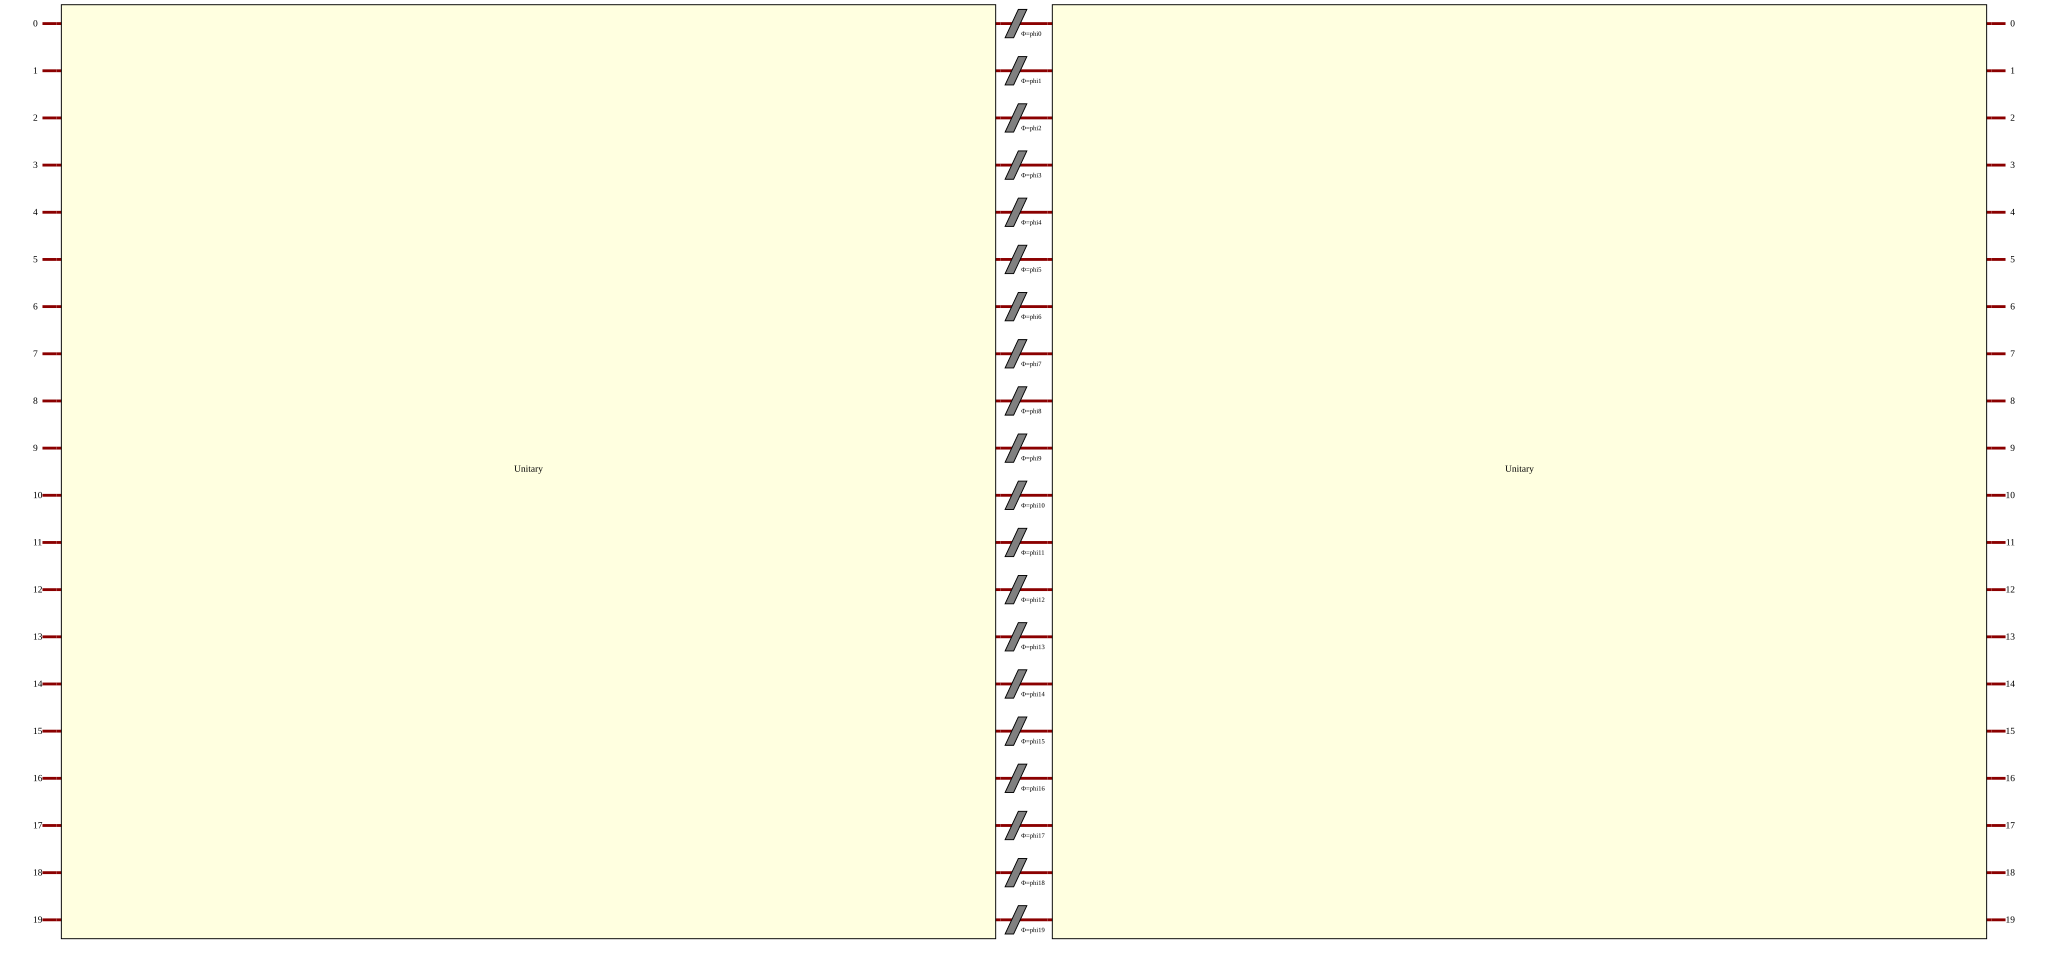

In [61]:
M = N_MODES
phi = [pcvl.P(f"phi{i}") for i in range(M)]          # data-dependent phases

def mesh(prefix):
    return pcvl.GenericInterferometer(
        M, lambda i: pcvl.BS() // pcvl.PS(pcvl.P(f"{prefix}{i}")),
        shape=pcvl.InterferometerShape.RECTANGLE)

# Random, frozen reservoir meshes, collapsed into fixed unitaries (MerLin needs every
# non-input parameter to be fixed, and this is the same optical transformation).
mesh_a, mesh_b = mesh("a"), mesh("b")
for p in mesh_a.get_parameters() + mesh_b.get_parameters():
    p.set_value(rng.uniform(0, 2 * np.pi))

circuit = pcvl.Circuit(M)
circuit.add(0, pcvl.Unitary(pcvl.Matrix(mesh_a.compute_unitary())))
for i in range(M):
    circuit.add(i, pcvl.PS(phi[i]))
circuit.add(0, pcvl.Unitary(pcvl.Matrix(mesh_b.compute_unitary())))

input_state = [1] * N_PHOTONS + [0] * (M - N_PHOTONS)
from math import comb
print(f"{M} modes, {N_PHOTONS} photons -> {comb(M + N_PHOTONS - 1, N_PHOTONS)} reservoir features")
pcvl.pdisplay(circuit)

In [62]:
# MerLin QuantumLayer: exact output probabilities (same as Perceval SLOS), batched in PyTorch
qlayer = ML.QuantumLayer(
    input_size=M,
    circuit=circuit,
    trainable_parameters=[],                 # reservoir is fixed
    input_parameters=["phi"],                # PCA values (in [0, 2*pi]) are used directly as phases
    input_state=input_state,
    measurement_strategy=ML.MeasurementStrategy.probs(computation_space=ML.ComputationSpace.FOCK),
    device=torch.device(DEVICE),
).eval()
KEYS = qlayer.output_keys                    # occupation pattern of each output column (fixed order)

def reservoir(P):
    """Map (n, N_MODES) phases -> (n, len(KEYS)) output-state probabilities."""
    assert P.shape[1] == M, f"expected {M} input columns, got {P.shape[1]}"
    X = torch.tensor(P, dtype=torch.float32, device=DEVICE)
    with torch.no_grad():
        out = [qlayer(X[i:i + BATCH_SIZE]).cpu() for i in range(0, len(X), BATCH_SIZE)]
    return torch.cat(out).double().numpy()

t0 = time.time()
R_tr = reservoir(P_tr)
R_te = reservoir(P_te)
print(f"reservoir states: train {R_tr.shape}, test {R_te.shape}  ({time.time()-t0:.1f}s on {DEVICE})")
print("probability sum check:", R_tr.sum(1).min().round(6), R_tr.sum(1).max().round(6))

# Sanity check against Perceval's exact SLOS simulator on a few training records
sim = Simulator(SLOSBackend())
for r in range(3):
    for p, v in zip(phi, P_tr[r]): p.set_value(float(v))
    sim.set_circuit(circuit)
    d = sim.probs(pcvl.BasicState(input_state))
    ref = np.array([d.get(pcvl.BasicState(list(k)), 0.0) for k in KEYS])
    assert np.abs(ref - R_tr[r]).max() < 1e-5, "MerLin and SLOS disagree"
print("MerLin matches Perceval SLOS on sample records")

reservoir states: train (6500, 8855), test (7047, 8855)  (1.0s on cuda)
probability sum check: 0.999999 1.000001
MerLin matches Perceval SLOS on sample records


## 3. Training process: learn attacks or learn normality?

We compare three ways to make a decision:

All three use a small neural network (**MLP**, multi-layer perceptron) as the final trained model:

- **Quantum classifier** (MLP classifier on the photonic-reservoir output): sees labeled normal and DoS examples. It learns to separate those known classes and uses a 0.5 probability cutoff. It has not been trained to recognize every kind of novelty.
- **Quantum anomaly detector** (MLP autoencoder on the photonic-reservoir output): sees only normal training examples. An autoencoder is an MLP trained to reproduce its own input through a narrow middle layer, so it learns to rebuild *normal* traffic well. A record it rebuilds badly (high reconstruction error) is unusual.
- **Classical anomaly detector** (MLP autoencoder on the PCA values): the same kind of model and the same normal-only training, but it skips the photonic circuit and works directly on the PCA numbers. It is the no-quantum comparison: any difference from the quantum anomaly detector comes from the reservoir features alone.

For each autoencoder, 20% of the normal training records are held back (never used for fitting) and the alarm cutoff is the 95th percentile of their reconstruction errors. In plain language, the model would raise a warning on about 5% of normal traffic it has not memorised. The test false-alarm rate may still differ from 5%, because unseen test traffic can have a different distribution.

### The two pipelines at a glance

Both pipelines share the same fixed photonic reservoir; only the final small model (purple) is trained, and the two differ in what that model learns from.

**Novelty mode:** the MLP autoencoder sees only normal training traffic and flags anything that looks unusual, which is how it can raise an alarm on never-seen (zero-day) attacks.

**Classifier mode:** the MLP classifier learns from labelled normal and DoS examples, so it recognises the attack type it was shown but has no explicit notion of "new".

![System pipeline pipeline](figures/fig1_pipeline.png)




In [63]:
# Plain-language model names used in every table and plot below
NAME_Q_CLF = "Quantum classifier"          # MLP classifier on photonic-reservoir features (normal + DoS labels)
NAME_Q_IF = "Quantum anomaly detector"     # MLP autoencoder on photonic-reservoir features (normal only)
NAME_C_IF = "Classical anomaly detector"   # MLP autoencoder directly on the PCA values (no quantum part)

normal_train = train.family.eq('normal').to_numpy()

# ---- Classifier mode: MLP classifier on labelled normal + DoS ----
rs = StandardScaler().fit(R_tr)
clf = MLPClassifier(hidden_layer_sizes=(64,), alpha=1e-3, early_stopping=True,
                    max_iter=300, random_state=SEED)
clf.fit(rs.transform(R_tr), y_train)
score_q = clf.predict_proba(rs.transform(R_te))[:, 1]
pred_q = (score_q >= 0.5).astype(int)

# ---- Novelty mode: MLP autoencoder trained on normal traffic only ----
# Anomaly score = reconstruction error. The cutoff comes from normal records held out
# from fitting, so it is not biased low by records the autoencoder has memorised.
def fit_autoencoder(X_normal, X_test, seed=SEED):
    """Fit an MLP autoencoder on normal rows; return (test scores, cutoff, fitted model)."""
    X_fit, X_val = train_test_split(X_normal, test_size=0.2, random_state=seed)
    sc = StandardScaler().fit(X_fit)
    d = X_normal.shape[1]
    bottleneck = int(np.clip(d // 4, 2, 32))            # narrow middle layer, always < input size
    hidden = (min(128, 4 * bottleneck), bottleneck, min(128, 4 * bottleneck))
    ae = MLPRegressor(hidden_layer_sizes=hidden, alpha=1e-4, early_stopping=True,
                      max_iter=300, random_state=seed)
    ae.fit(sc.transform(X_fit), sc.transform(X_fit))
    err = lambda X: np.mean((ae.predict(sc.transform(X)) - sc.transform(X)) ** 2, axis=1)
    cutoff = np.quantile(err(X_val), 0.95)
    return err(X_test), cutoff, ae

t0 = time.time()
score_ad_q, thr_ad_q, ae_q = fit_autoencoder(R_tr[normal_train], R_te)
pred_ad_q = (score_ad_q > thr_ad_q).astype(int)
score_ad_c, thr_ad_c, ae_c = fit_autoencoder(Z_tr[normal_train], Z_te)
pred_ad_c = (score_ad_c > thr_ad_c).astype(int)

print(f"MLP classifier hidden layers: {clf.hidden_layer_sizes}")
print(f"Autoencoder layers: quantum {ae_q.hidden_layer_sizes}, classical {ae_c.hidden_layer_sizes}")
print(f"Normal-only training size (both anomaly detectors): {normal_train.sum()} (80% fit, 20% for the cutoff)")
print(f"95th-percentile cutoffs: {NAME_Q_IF}={thr_ad_q:.4f}, {NAME_C_IF}={thr_ad_c:.4f}  ({time.time()-t0:.1f}s)")


MLP classifier hidden layers: (64,)
Autoencoder layers: quantum (128, 32, 128), classical (20, 5, 20)
Normal-only training size (both anomaly detectors): 4000 (80% fit, 20% for the cutoff)
95th-percentile cutoffs: Quantum anomaly detector=0.1655, Classical anomaly detector=0.6221  (205.8s)


## 4. Compare with classical detectors

The next cells print standard classification scores and then look at each attack family separately. In particular:

- **ROC-AUC** measures whether attacks tend to receive higher anomaly scores than normal records across many possible cutoffs. A score near 1 is strong ranking; 0.5 is roughly chance.
- **R2L recall** is the share of held-out R2L attacks that the model catches at the chosen cutoff. Higher means fewer zero-day examples are missed.
- **Normal false-positive rate (FPR)** is the share of normal test records incorrectly flagged as attacks. Lower means fewer unnecessary alerts.

No single number is enough: a model that flags every connection catches all attacks but also creates an unusable flood of false alarms. Consider recall together with FPR.

In [64]:
names = ['normal', 'anomaly']
models = [
    (NAME_Q_CLF, pred_q),
    (NAME_Q_IF, pred_ad_q),
    (NAME_C_IF, pred_ad_c),
]
for title, pred in models:
    print("=" * 70, f"\n{title}\n" + "=" * 70)
    print(classification_report(y_test, pred, target_names=names, digits=3, zero_division=0))


Quantum classifier
              precision    recall  f1-score   support

      normal      0.543     0.998     0.704      3000
     anomaly      0.997     0.378     0.548      4047

    accuracy                          0.642      7047
   macro avg      0.770     0.688     0.626      7047
weighted avg      0.804     0.642     0.614      7047

Quantum anomaly detector
              precision    recall  f1-score   support

      normal      0.761     0.955     0.847      3000
     anomaly      0.959     0.778     0.859      4047

    accuracy                          0.853      7047
   macro avg      0.860     0.866     0.853      7047
weighted avg      0.875     0.853     0.854      7047

Classical anomaly detector
              precision    recall  f1-score   support

      normal      0.775     0.957     0.856      3000
     anomaly      0.961     0.794     0.870      4047

    accuracy                          0.863      7047
   macro avg      0.868     0.875     0.863      7047
wei

,n,seen_in_train,Quantum classifier recall,Quantum anomaly detector recall,Classical anomaly detector recall
family,,,,,
dos,1500,True,0.995,0.960,0.969
probe,1500,False,0.018,0.930,0.823
r2l,995,False,0.009,0.276,0.489
u2r,52,False,0.000,0.731,0.731
normal (specificity),3000,True,0.998,0.955,0.957


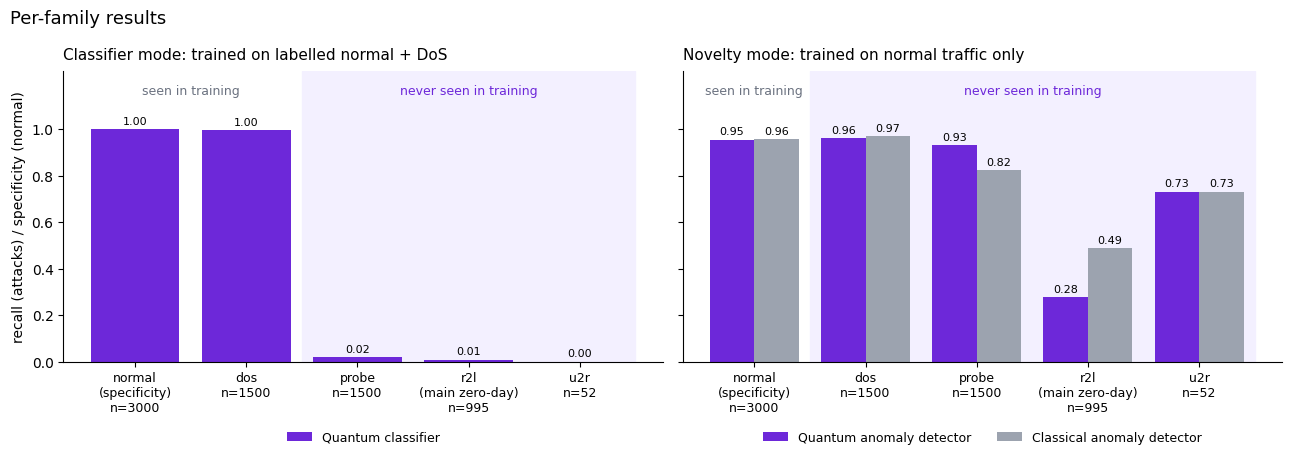

In [65]:
fam = test.family.values
models = {
    NAME_Q_CLF: pred_q,
    NAME_Q_IF: pred_ad_q,
    NAME_C_IF: pred_ad_c,
}
rows = []
for f in ['dos', 'probe', 'r2l', 'u2r']:
    m = fam == f
    row = {'family': f, 'n': int(m.sum()), 'seen_in_train': f == 'dos'}
    row.update({f'{name} recall': pred[m].mean() for name, pred in models.items()})
    rows.append(row)
m = fam == 'normal'
row = {'family': 'normal (specificity)', 'n': int(m.sum()), 'seen_in_train': True}
row.update({f'{name} recall': 1 - pred[m].mean() for name, pred in models.items()})
rows.append(row)
res = pd.DataFrame(rows).set_index('family')
display(res.round(3))

# Two panels: classifier vs novelty. Shading marks families the model never saw in training
# (the classifier saw normal + DoS; the novelty detectors saw normal only).
TRAINED, BASELINE, UNSEEN_BG = '#6D28D9', '#9CA3AF', '#F3F0FF'
names = list(models)
order = ['normal (specificity)', 'dos', 'probe', 'r2l', 'u2r']
tick = {'normal (specificity)': 'normal\n(specificity)', 'r2l': 'r2l\n(main zero-day)'}
xlabels = [f"{tick.get(f, f)}\nn={res.loc[f, 'n']}" for f in order]
x = np.arange(len(order))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
panels = [
    (axes[0], 'Classifier mode: trained on labelled normal + DoS', [(names[0], TRAINED)], 2),
    (axes[1], 'Novelty mode: trained on normal traffic only', [(names[1], TRAINED), (names[2], BASELINE)], 1),
]
for ax, title, series, n_seen in panels:
    ax.axvspan(n_seen - 0.5, len(order) - 0.5, color=UNSEEN_BG, zorder=0)
    ax.text((n_seen - 1) / 2, 1.15, 'seen in training', ha='center', fontsize=9, color='#6B7280')
    ax.text((n_seen + len(order) - 1) / 2, 1.15, 'never seen in training', ha='center', fontsize=9, color=TRAINED)
    w = 0.8 / len(series)
    for j, (name, color) in enumerate(series):
        vals = res.loc[order, f'{name} recall'].to_numpy()
        bars = ax.bar(x - 0.4 + w * (j + 0.5), vals, w, color=color, label=name, zorder=2)
        ax.bar_label(bars, fmt='%.2f', fontsize=8, padding=2)
    ax.set_xticks(x, xlabels, fontsize=9)
    ax.set_ylim(0, 1.25); ax.set_yticks(np.linspace(0, 1, 6))
    ax.set_title(title, fontsize=11, loc='left', pad=8)
    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False, fontsize=9)
axes[0].set_ylabel('recall (attacks) / specificity (normal)')
fig.suptitle('Per-family results', fontsize=13, x=0.01, ha='left')
plt.tight_layout(); plt.show()


In [66]:
normal_test = fam == 'normal'
r2l_test = fam == 'r2l'
metric_models = [
    (NAME_Q_CLF, score_q, pred_q, '0.5 probability'),
    (NAME_Q_IF, score_ad_q, pred_ad_q, f'held-out normal p95 = {thr_ad_q:.4f}'),
    (NAME_C_IF, score_ad_c, pred_ad_c, f'held-out normal p95 = {thr_ad_c:.4f}'),
]
metrics = []
for name, score, pred, cutoff in metric_models:
    metrics.append({
        'model': name,
        'ROC-AUC': roc_auc_score(y_test, score),
        'r2l zero-day recall': pred[r2l_test].mean(),
        'normal FPR': pred[normal_test].mean(),
        'decision threshold': cutoff,
    })
display(pd.DataFrame(metrics).set_index('model').round(3))
print("Confusion matrices (true rows, predicted columns; normal, anomaly):")
for name, _, pred, _ in metric_models:
    print(f"{name}:\n{confusion_matrix(y_test, pred)}")


,ROC-AUC,r2l zero-day recall,normal FPR,decision threshold
model,,,,
Quantum classifier,0.591,0.009,0.002,0.5 probability
Quantum anomaly detector,0.960,0.276,0.045,held-out normal p95 = 0.1655
Classical anomaly detector,0.956,0.489,0.043,held-out normal p95 = 0.6221


Confusion matrices (true rows, predicted columns; normal, anomaly):
Quantum classifier:
[[2995    5]
 [2518 1529]]
Quantum anomaly detector:
[[2864  136]
 [ 899 3148]]
Classical anomaly detector:
[[2871  129]
 [ 835 3212]]


### What should we learn from the result?

A supervised classifier learns the difference between **normal and the known DoS examples**. It is not asked to learn what normal traffic looks like in general, so a new attack that does not resemble DoS may be mistaken for normal. A normal-only Isolation Forest has a more suitable goal for novelty detection: identify records that differ from the examples of normal traffic. That makes its learning objective a better fit for zero-day detection, but it still cannot guarantee that every new attack will look unusual.

In the saved run, the normal-only detectors have ROC-AUC around 0.90, while the supervised QORC readout is lower. At the selected threshold, however, R2L recall is modest; the PCA Isolation Forest catches more R2L examples than the reservoir Isolation Forest in this run. Thus the better anomaly-detection objective improves ranking overall, but it does **not** mean the QORC catches more of this particular zero-day family at the chosen alert rate.

The comparison also does not prove a quantum advantage: the photonic circuit is simulated, its settings are random and fixed, and it only transforms the four PCA values. Here, reservoir and PCA Isolation Forest ROC-AUC are very close. To support a stronger claim, repeat with multiple random seeds and compare against classical nonlinear feature maps of the same size.